# Earthquake Alert Prediction (M4.5+, 1976–2024)

**Goal:** predict the alert level of a large earthquake (`green`, `yellow`, `orange`, `red`) from its magnitude, depth, location and region.

**The catch this notebook deals with:** about 96% of events are `green`. A model that always answers "green" already scores ~96% accuracy, so accuracy is a misleading metric here. Everything below is measured against that baseline using macro-F1, balanced accuracy, per-class recall and PR-AUC.

**Contents:** 1. Load & clean · 2. Target & baseline · 3. Feature engineering · 4. EDA · 5. Model comparison · 6. Does region help? · 7. Tuning on past data, testing on future data · 8. Final model results · 9. Feature importance · 10. Save model · 11. Conclusions

In [1]:
#import os; 
#print(os.getcwd())

C:\Users\DELL\earthquake-alert-prediction\notebooks


## 1. Load & clean

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_PATH = Path("../data/earthquakes.csv")
IMG_DIR = Path("../images"); IMG_DIR.mkdir(exist_ok=True)

def save_fig(name):
    plt.savefig(IMG_DIR / name, dpi=130, bbox_inches="tight")

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (7717, 23)


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource,Alert
0,1976-03-25 00:41:20.500000+00:00,35.590000,-90.480000,15.000,4.62,mw,NaN,NaN,NaN,NaN,...,"8 km NW of Marked Tree, Arkansas",earthquake,NaN,NaN,NaN,0.0,reviewed,nm,nm,green
1,1979-10-16 06:58:43.450000+00:00,32.998667,-115.557500,14.190,5.80,ml,7.0,79.0,0.05768,0.17,...,"3km NW of Brawley, CA",earthquake,1.03,1.78,NaN,0.0,reviewed,ci,ci,yellow
2,1980-07-27 18:52:21.600000+00:00,38.190000,-83.950000,10.000,5.00,md,NaN,NaN,NaN,NaN,...,"2 km SW of Sharpsburg, Kentucky",earthquake,NaN,NaN,NaN,NaN,reviewed,se,se,green
3,1981-04-19 09:02:50.520000+00:00,35.816000,-117.816333,4.766,4.70,ml,13.0,135.0,NaN,0.66,...,"16km SSE of Little Lake, CA",earthquake,2.51,31.61,0.424,9.0,reviewed,ci,ci,green
4,1981-04-26 12:09:28.290000+00:00,33.095500,-115.624500,18.904,5.75,ml,81.0,34.0,NaN,0.34,...,"The 1981 Westmorland, California Earthquake",earthquake,0.56,0.67,0.161,6.0,reviewed,ci,ci,green


In [3]:
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print("Columns with missing values (% of rows):")
print(missing[missing > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("Unique event types:\n", df["type"].value_counts())

Columns with missing values (% of rows):
nst                68.8
magError           28.9
magNst             26.8
horizontalError    15.8
dmin                9.1
gap                 4.2
depthError          2.7
rms                 0.3
dtype: float64

Duplicate rows: 0
Unique event types:
 type
earthquake           7699
volcanic eruption      17
nuclear explosion       1
Name: count, dtype: int64


**Cleaning decisions**
- Only 18 rows are not earthquakes (17 volcanic eruptions, 1 nuclear explosion, all `green`). They are removed because the project is about earthquakes.
- Station-quality columns (`nst`, `gap`, `dmin`, `magError`, ...) have up to 69% missing values. They describe how well an event was *measured*, not how damaging it is, so they are not used as model inputs. `latitude`, `longitude`, `depth`, `mag` and `place` have no missing values.
- **No outlier removal.** An earlier version of this project dropped IQR outliers on `mag`, which throws away exactly the large earthquakes most likely to trigger orange/red alerts.

In [4]:
df = df[df["type"] == "earthquake"].reset_index(drop=True)
print("Rows after keeping earthquakes only:", len(df))

Rows after keeping earthquakes only: 7699


## 2. Target and the 'always green' baseline

        count  percent
Alert                 
green    7368    95.70
yellow    246     3.20
orange     52     0.68
red        33     0.43

Always predicting 'green' gives accuracy = 95.7%


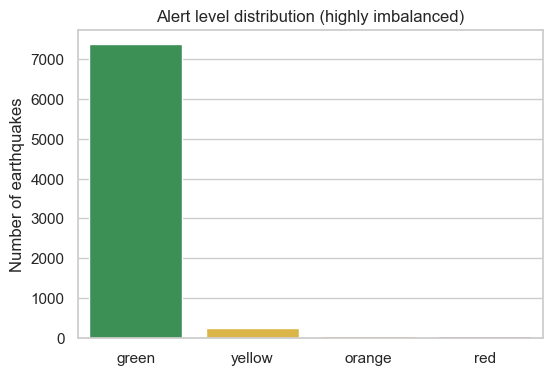

In [5]:
ALERT_ORDER = ["green", "yellow", "orange", "red"]
ALERT_COLORS = {"green": "#2e9e4f", "yellow": "#f2c230", "orange": "#f08a24", "red": "#d0342c"}

counts = df["Alert"].value_counts().reindex(ALERT_ORDER)
print(pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(2)}))

baseline_acc = counts.max() / counts.sum()
print(f"\nAlways predicting 'green' gives accuracy = {baseline_acc:.1%}")

plt.figure(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, palette=ALERT_COLORS)
plt.title("Alert level distribution (highly imbalanced)")
plt.ylabel("Number of earthquakes"); plt.xlabel("")
save_fig("alert_distribution.png")
plt.show()

## 3. Feature engineering
- **`time`** is parsed with `format="mixed"` (timestamps with and without fractional seconds). A fixed format string fails on most rows and silently produces empty dates.
- **`region`** is the last comma-separated part of `place` (for example `"Indonesia"`, `"Japan"`, `"CA"`). It is a proxy for *where people live and how vulnerable buildings are*, which matters for damage-based alerts but isn't in the numeric columns. Regions with fewer than 20 events are grouped as `Other`.
- `depth` has a few tiny negative values (above sea level); they are clipped to 0.

In [6]:
df["time"] = pd.to_datetime(df["time"], utc=True, format="mixed")
print("Unparsed timestamps:", df["time"].isna().sum())
df["year"] = df["time"].dt.year

df["region"] = df["place"].str.split(",").str[-1].str.strip()
region_counts = df["region"].value_counts()
df["region_grp"] = np.where(df["region"].map(region_counts) >= 20, df["region"], "Other")

df["depth"] = df["depth"].clip(lower=0)
df["any_alert"] = (df["Alert"] != "green").astype(int)

print("Distinct regions:", df["region"].nunique(), "-> grouped into", df["region_grp"].nunique())
df[["time", "place", "region_grp", "mag", "depth", "Alert"]].head()

Unparsed timestamps: 0
Distinct regions: 276 -> grouped into 71


,time,place,region_grp,mag,depth,Alert
0,1976-03-25 00:41:20.500000+00:00,"8 km NW of Marked Tree, Arkansas",Other,4.62,15.000,green
1,1979-10-16 06:58:43.450000+00:00,"3km NW of Brawley, CA",CA,5.80,14.190,yellow
2,1980-07-27 18:52:21.600000+00:00,"2 km SW of Sharpsburg, Kentucky",Other,5.00,10.000,green
3,1981-04-19 09:02:50.520000+00:00,"16km SSE of Little Lake, CA",CA,4.70,4.766,green
4,1981-04-26 12:09:28.290000+00:00,"The 1981 Westmorland, California Earthquake",Other,5.75,18.904,green


## 4. Exploratory data analysis

            rate     n
mag                   
(4.0, 5.0]   0.1   681
(5.0, 5.5]   1.9  2798
(5.5, 6.0]   3.7  2945
(6.0, 6.5]   8.6   848
(6.5, 7.0]  15.3   294
(7.0, 7.5]  33.0    88
(7.5, 9.0]  46.7    45


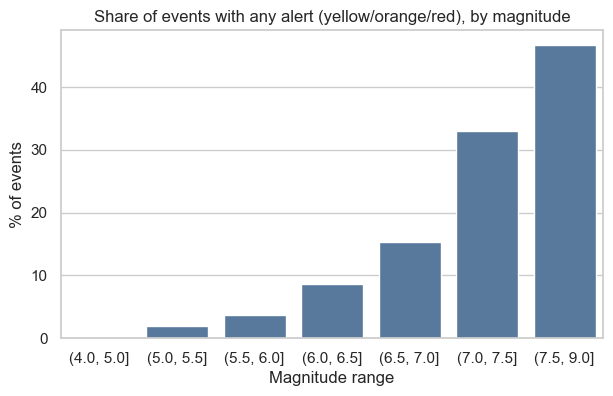

In [7]:
mag_bins = pd.cut(df["mag"], [4, 5, 5.5, 6, 6.5, 7, 7.5, 9])
by_mag = df.groupby(mag_bins, observed=True)["any_alert"].agg(rate="mean", n="size")
by_mag["rate"] = (by_mag["rate"] * 100).round(1)
print(by_mag)

plt.figure(figsize=(7, 4))
sns.barplot(x=by_mag.index.astype(str), y=by_mag["rate"], color="#4c78a8")
plt.title("Share of events with any alert (yellow/orange/red), by magnitude")
plt.ylabel("% of events"); plt.xlabel("Magnitude range")
save_fig("alert_rate_by_magnitude.png")
plt.show()

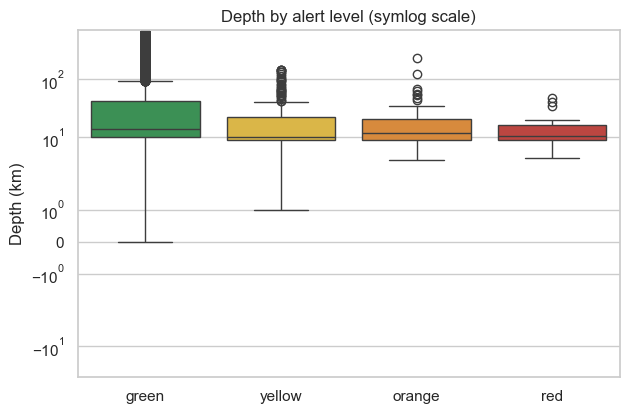

Alert
green     14.0
yellow    10.1
orange    12.0
red       10.3
Name: median depth (km), dtype: float64


In [8]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x="Alert", y="depth", order=ALERT_ORDER, palette=ALERT_COLORS)
plt.yscale("symlog")
plt.title("Depth by alert level (symlog scale)")
plt.ylabel("Depth (km)"); plt.xlabel("")
save_fig("depth_by_alert.png")
plt.show()

print(df.groupby("Alert")["depth"].median().reindex(ALERT_ORDER).round(1).rename("median depth (km)"))

             rate    n
region                
China        53.7   82
Iran         41.2   80
Greece       25.0   60
Mexico       12.0  150
MX            8.2   61
Peru          7.8  103
Taiwan        4.9   81
New Zealand   4.8  210
Japan         4.7  318
Philippines   3.8  288
CA            3.5  171
Chile         3.3  302


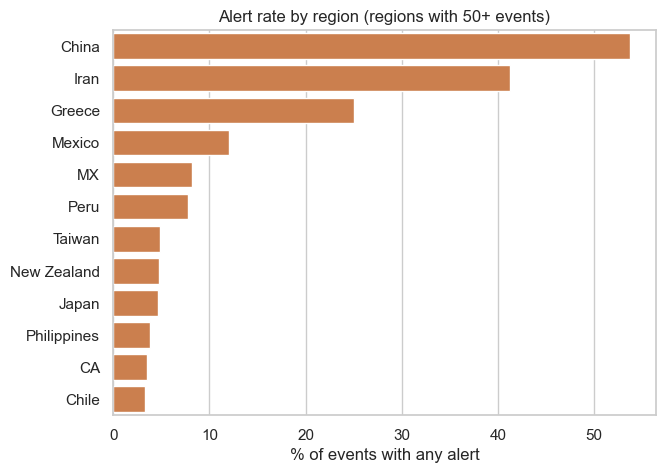

In [9]:
reg = df.groupby("region")["any_alert"].agg(rate="mean", n="size")
reg = reg[reg["n"] >= 50].sort_values("rate", ascending=False).head(12)
reg["rate"] = (reg["rate"] * 100).round(1)
print(reg)

plt.figure(figsize=(7, 5))
sns.barplot(y=reg.index, x=reg["rate"], color="#e07b39")
plt.title("Alert rate by region (regions with 50+ events)")
plt.xlabel("% of events with any alert"); plt.ylabel("")
save_fig("alert_rate_by_region.png")
plt.show()

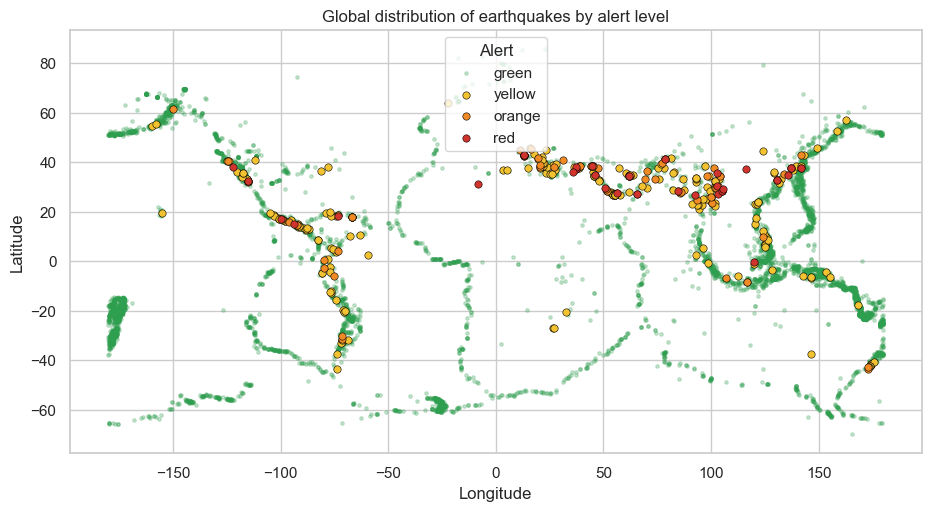

In [10]:
plt.figure(figsize=(11, 5.5))
g = df[df["Alert"] == "green"]
plt.scatter(g["longitude"], g["latitude"], s=6, c=ALERT_COLORS["green"], alpha=0.25, label="green")
for a in ["yellow", "orange", "red"]:
    s = df[df["Alert"] == a]
    plt.scatter(s["longitude"], s["latitude"], s=28, c=ALERT_COLORS[a], edgecolor="black", linewidth=0.4, label=a)
plt.legend(title="Alert"); plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("Global distribution of earthquakes by alert level")
save_fig("map_by_alert.png")
plt.show()

Events per period:
Alert         green  yellow  orange  red
year                                    
(1975, 2000]     35       1       0    0
(2000, 2010]     96       6       0    1
(2010, 2015]   1625      50      14    5
(2015, 2020]   2894      90      23   10
(2020, 2025]   2718      99      15   17


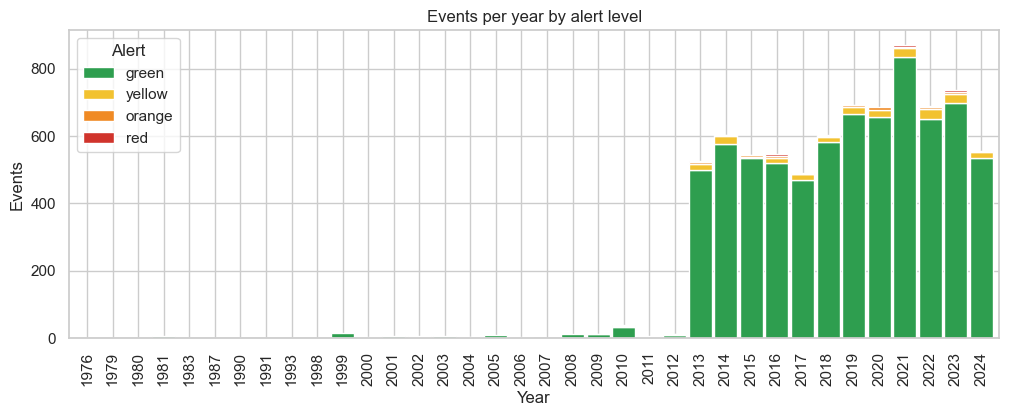

In [11]:
yearly = pd.crosstab(df["year"], df["Alert"]).reindex(columns=ALERT_ORDER)
print("Events per period:")
print(pd.crosstab(pd.cut(df["year"], [1975, 2000, 2010, 2015, 2020, 2025]), df["Alert"]).reindex(columns=ALERT_ORDER))

yearly[ALERT_ORDER].plot(kind="bar", stacked=True, figsize=(12, 4), color=[ALERT_COLORS[a] for a in ALERT_ORDER], width=0.9)
plt.title("Events per year by alert level"); plt.ylabel("Events"); plt.xlabel("Year")
save_fig("events_per_year.png")
plt.show()

**What the EDA shows**
- Higher magnitude clearly raises the chance of an alert, but even at M7.5+ many events stay green, so magnitude alone is not enough.
- Orange/red events are much *shallower* than green ones (median depth ~10–12 km vs ~14 km overall, with green having a long deep tail up to 670 km).
- Alert rates differ strongly by region (for example China, Iran and Mexico versus Tonga or the South Sandwich Islands), consistent with alerts depending on population and building vulnerability.
- Almost all records are from 2010 onward, so I also test on a time-based split later.

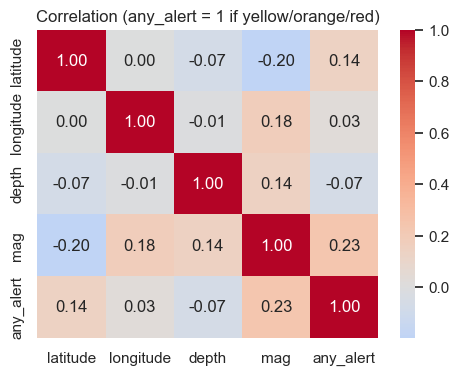

In [12]:
num_core = ["latitude", "longitude", "depth", "mag"]
plt.figure(figsize=(5.5, 4))
sns.heatmap(df[num_core + ["any_alert"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (any_alert = 1 if yellow/orange/red)")
save_fig("correlation_heatmap.png")
plt.show()

## 5. Model comparison (stratified 5-fold cross-validation)

Every row is predicted by a model that never saw it (`cross_val_predict`), using **stratified** folds so each fold keeps the rare classes. Metrics:
- **Macro-F1** and **balanced accuracy** treat all four classes equally.
- **Per-class recall** shows how many real yellow/orange/red events each model catches.
- Accuracy is shown only to demonstrate why it is misleading.

Class weights (`class_weight="balanced"`) make mistakes on rare classes cost more. KNN has no such option, so it is included as-is.

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             precision_score, average_precision_score, classification_report,
                             confusion_matrix, precision_recall_curve)

NUM_COLS = ["latitude", "longitude", "depth", "mag"]
CAT_COLS = ["region_grp"]
X_all = df[NUM_COLS + CAT_COLS]
y_all = df["Alert"]

def make_pipeline(model, use_region=True):
    transformers = [("num", StandardScaler(), NUM_COLS)]
    if use_region:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS))
    return Pipeline([("prep", ColumnTransformer(transformers)), ("model", model)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def summarize(name, y_true, y_pred):
    rec = recall_score(y_true, y_pred, labels=ALERT_ORDER, average=None, zero_division=0)
    row = {"model": name,
           "accuracy": accuracy_score(y_true, y_pred),
           "balanced_acc": balanced_accuracy_score(y_true, y_pred),
           "macro_f1": f1_score(y_true, y_pred, average="macro"),
           }
    row.update({f"recall_{a}": r for a, r in zip(ALERT_ORDER, rec)})
    return row

In [14]:
models = {
    "Always 'green' (baseline)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (no weights)": LogisticRegression(max_iter=2000),
    "Logistic Regression (balanced)": LogisticRegression(class_weight="balanced", max_iter=2000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (balanced)": SVC(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest (no weights)": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting (balanced)": HistGradientBoostingClassifier(class_weight="balanced", max_depth=4, learning_rate=0.05, max_iter=200, random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    pred = cross_val_predict(make_pipeline(model), X_all, y_all, cv=cv)
    rows.append(summarize(name, y_all, pred))

results = pd.DataFrame(rows).set_index("model").sort_values("macro_f1", ascending=False)
results.round(3)

,accuracy,balanced_acc,macro_f1,recall_green,recall_yellow,recall_orange,recall_red
model,,,,,,,
Random Forest (balanced),0.953,0.485,0.478,0.978,0.443,0.154,0.364
KNN (k=5),0.958,0.368,0.408,0.992,0.195,0.135,0.152
Gradient Boosting (balanced),0.905,0.483,0.394,0.923,0.614,0.154,0.242
Logistic Regression (balanced),0.836,0.515,0.333,0.855,0.455,0.173,0.576
Logistic Regression (no weights),0.959,0.302,0.328,0.997,0.142,0.038,0.030
SVM (balanced),0.814,0.459,0.308,0.831,0.500,0.173,0.333
Random Forest (no weights),0.959,0.268,0.276,0.999,0.073,0.000,0.000
Always 'green' (baseline),0.957,0.250,0.245,1.000,0.000,0.000,0.000


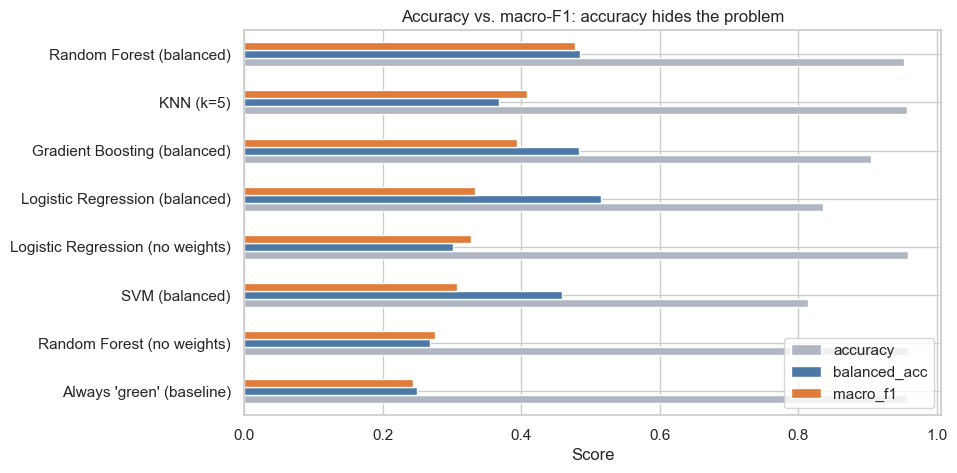

In [15]:
plot_df = results[["accuracy", "balanced_acc", "macro_f1"]].sort_values("macro_f1")
plot_df.plot(kind="barh", figsize=(9, 5), color=["#b0b7c3", "#4c78a8", "#e07b39"])
plt.title("Accuracy vs. macro-F1: accuracy hides the problem")
plt.xlabel("Score"); plt.ylabel(""); plt.legend(loc="lower right")
save_fig("model_comparison.png")
plt.show()

**Reading the table**
- The baseline that always says "green" has 95.7% accuracy but a macro-F1 of only 0.24.
- The unweighted models (including the Random Forest that scored "96.2%" in my first version) look great on accuracy, but they catch almost no orange/red events. Accuracy is the wrong scorecard for this problem.
- Balanced Random Forest has the best macro-F1 (0.48) while keeping accuracy high (95.3%). Logistic Regression and Gradient Boosting with balanced weights catch more rare events but raise many false alarms, lowering accuracy.

## 6. Does the region feature help?

Random Forest with and without `region_grp`, repeated over 3 different CV shuffles to see how much of the difference is noise. For the "any alert" view I use **PR-AUC** (average precision) of P(alert) = 1 − P(green), where a random model would score about 0.04 (the alert prevalence).

In [16]:
def repeated_cv(use_region, seeds=(0, 1, 2)):
    out = []
    for s in seeds:
        skf = StratifiedKFold(5, shuffle=True, random_state=s)
        pipe = make_pipeline(RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
                             class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1), use_region)
        X = X_all if use_region else X_all[NUM_COLS]
        proba = cross_val_predict(pipe, X, y_all, cv=skf, method="predict_proba")
        classes = np.array(sorted(y_all.unique()))
        pred = classes[proba.argmax(axis=1)]
        p_alert = 1 - proba[:, list(classes).index("green")]
        out.append({"macro_f1": f1_score(y_all, pred, average="macro"),
                    "balanced_acc": balanced_accuracy_score(y_all, pred),
                    "alert_PR_AUC": average_precision_score(df["any_alert"], p_alert)})
    o = pd.DataFrame(out)
    return o.mean().add_suffix("_mean").to_dict() | o.std().add_suffix("_std").to_dict()

region_cmp = pd.DataFrame({"4 numeric features only": repeated_cv(False),
                           "numeric + region": repeated_cv(True)}).T
region_cmp.round(3)

,macro_f1_mean,balanced_acc_mean,alert_PR_AUC_mean,macro_f1_std,balanced_acc_std,alert_PR_AUC_std
4 numeric features only,0.439,0.432,0.609,0.009,0.007,0.011
numeric + region,0.446,0.455,0.635,0.006,0.009,0.002


**Result:** adding region gives a small gain in "any alert" PR-AUC (0.609 → 0.635) and balanced accuracy, but macro-F1 barely moves (0.439 vs 0.446, within run-to-run noise of about ±0.01). The honest reading: region is a sensible, cheap feature that helps a little, but the big improvement over the first version comes from handling class imbalance and evaluating correctly, not from feature engineering. I keep it in the final model because it is available at prediction time and makes domain sense.

## 7. Hyperparameter tuning on the past, testing on the future

Cross-validation shuffles events randomly. A more realistic check for an alert system is to **train on earlier years and test on later ones**. I tune the Random Forest with `RandomizedSearchCV` (scoring = macro-F1) using only events up to 2019, then evaluate on 2020–2024.

In [17]:
from sklearn.model_selection import RandomizedSearchCV

train_mask = df["year"] <= 2019
X_tr, y_tr = X_all[train_mask], y_all[train_mask]
X_te, y_te = X_all[~train_mask], y_all[~train_mask]
print(f"Train: {len(X_tr)} events (<=2019) | Test: {len(X_te)} events (2020-2024)")
print("Test alerts:", y_te.value_counts().reindex(ALERT_ORDER).to_dict())

param_dist = {
    "model__n_estimators": [200, 300],
    "model__min_samples_leaf": [1, 2, 3, 5, 8],
    "model__max_depth": [None, 12, 20],
    "model__max_features": ["sqrt", 0.5],
}
base_rf = RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1)
search = RandomizedSearchCV(make_pipeline(base_rf), param_dist, n_iter=8, scoring="f1_macro",
                            cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                            random_state=RANDOM_STATE, n_jobs=1)
search.fit(X_tr, y_tr)
print("Best params:", search.best_params_)
print(f"Best CV macro-F1 (train years only): {search.best_score_:.3f}")

Train: 4165 events (<=2019) | Test: 3534 events (2020-2024)
Test alerts: {'green': 3375, 'yellow': 120, 'orange': 22, 'red': 17}
Best params: {'model__n_estimators': 200, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': 12}
Best CV macro-F1 (train years only): 0.451


In [18]:
default_rf = make_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                                  random_state=RANDOM_STATE, n_jobs=-1)).fit(X_tr, y_tr)
candidates = {"Always 'green'": DummyClassifier(strategy="most_frequent")}
rows = []
for name, est in [("Always 'green' (baseline)", make_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_tr, y_tr)),
                  ("Random Forest (default settings)", default_rf),
                  ("Random Forest (tuned)", search.best_estimator_)]:
    pred = est.predict(X_te)
    row = summarize(name, y_te, pred)
    if hasattr(est, "predict_proba") and name != "Always 'green' (baseline)":
        proba = est.predict_proba(X_te)
        row["alert_PR_AUC"] = average_precision_score((y_te != "green"), 1 - proba[:, list(est.classes_).index("green")])
    rows.append(row)
temporal = pd.DataFrame(rows).set_index("model")
print("Alert prevalence in test years:", round((y_te != "green").mean(), 3))
temporal.round(3)

Alert prevalence in test years: 0.045


,accuracy,balanced_acc,macro_f1,recall_green,recall_yellow,recall_orange,recall_red,alert_PR_AUC
model,,,,,,,,
Always 'green' (baseline),0.955,0.250,0.244,1.000,0.000,0.000,0.000,NaN
Random Forest (default settings),0.943,0.409,0.414,0.973,0.383,0.045,0.235,0.544
Random Forest (tuned),0.937,0.439,0.424,0.963,0.467,0.091,0.235,0.534


## 8. Final model: results in detail

The final configuration is the tuned balanced Random Forest with numeric features + region. To report results without any row being predicted by a model that saw it, I use out-of-fold predictions from the stratified 5-fold CV.

In [19]:
final_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
def final_model():
    return make_pipeline(RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE,
                                                n_jobs=-1, **final_params))

proba_oof = cross_val_predict(final_model(), X_all, y_all, cv=cv, method="predict_proba")
classes = np.array(sorted(y_all.unique()))            # alphabetical: green, orange, red, yellow
pred_oof = classes[proba_oof.argmax(axis=1)]

print(classification_report(y_all, pred_oof, labels=ALERT_ORDER, zero_division=0, digits=3))
final_summary = summarize("final", y_all, pred_oof)
print({k: round(v, 3) for k, v in final_summary.items() if k != "model"})

              precision    recall  f1-score   support

       green      0.987     0.955     0.970      7368
      yellow      0.279     0.524     0.364       246
      orange      0.138     0.173     0.154        52
         red      0.289     0.394     0.333        33

    accuracy                          0.933      7699
   macro avg      0.423     0.511     0.455      7699
weighted avg      0.956     0.933     0.943      7699

{'accuracy': 0.933, 'balanced_acc': 0.511, 'macro_f1': 0.455, 'recall_green': np.float64(0.955), 'recall_yellow': np.float64(0.524), 'recall_orange': np.float64(0.173), 'recall_red': np.float64(0.394)}


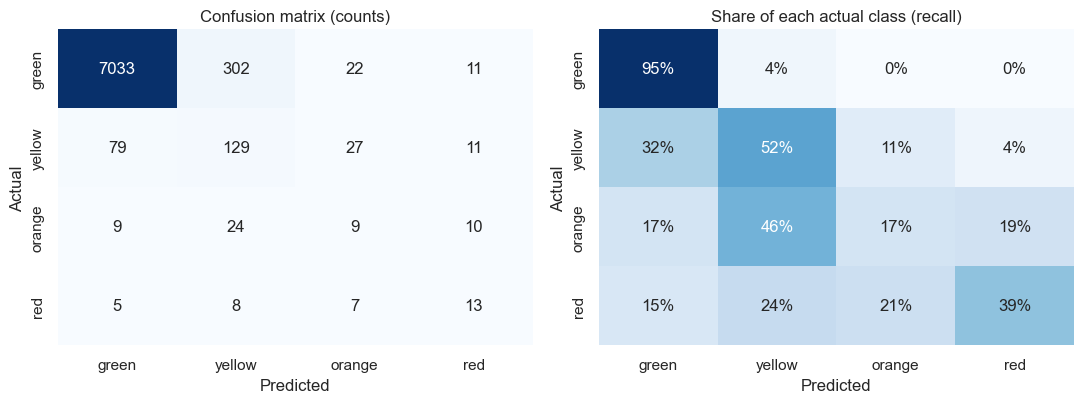

In [20]:
cm = confusion_matrix(y_all, pred_oof, labels=ALERT_ORDER)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ALERT_ORDER, yticklabels=ALERT_ORDER, ax=ax[0], cbar=False)
ax[0].set_title("Confusion matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
sns.heatmap(cm_norm, annot=True, fmt=".0%", cmap="Blues", xticklabels=ALERT_ORDER, yticklabels=ALERT_ORDER, ax=ax[1], cbar=False)
ax[1].set_title("Share of each actual class (recall)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")
plt.tight_layout(); save_fig("confusion_matrix.png"); plt.show()

### The practical view: "will this event trigger any alert?"
Because red (33) and orange (52) events are so rare, the most useful output is the probability that an event triggers *any* alert, P(alert) = 1 − P(green). Lowering the decision threshold catches more real alerts at the price of more false alarms. That trade-off is a business decision, so here is the full picture.

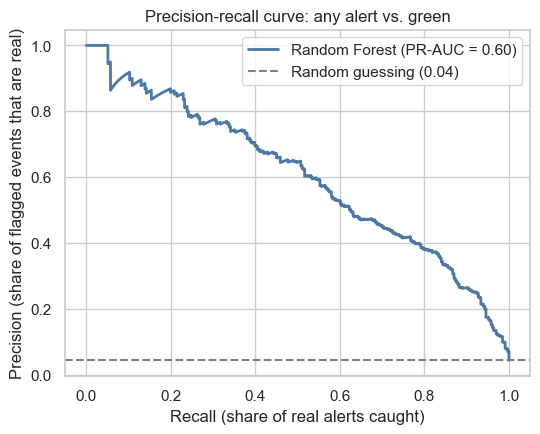

,recall (alerts caught),precision,events flagged (%)
threshold,,,
0.10,0.961,0.150,27.575
0.15,0.946,0.184,22.055
0.20,0.934,0.214,18.756
0.30,0.903,0.263,14.781
0.40,0.867,0.317,11.768
0.50,0.804,0.381,9.079


In [21]:
p_alert = 1 - proba_oof[:, list(classes).index("green")]
y_alert = df["any_alert"].values

prec, rec, thr = precision_recall_curve(y_alert, p_alert)
ap = average_precision_score(y_alert, p_alert)
plt.figure(figsize=(6, 4.5))
plt.plot(rec, prec, color="#4c78a8", lw=2, label=f"Random Forest (PR-AUC = {ap:.2f})")
plt.axhline(y_alert.mean(), color="grey", ls="--", label=f"Random guessing ({y_alert.mean():.2f})")
plt.xlabel("Recall (share of real alerts caught)"); plt.ylabel("Precision (share of flagged events that are real)")
plt.title("Precision-recall curve: any alert vs. green"); plt.legend()
save_fig("precision_recall_curve.png"); plt.show()

rows = []
for t in [0.10, 0.15, 0.20, 0.30, 0.40, 0.50]:
    flag = p_alert >= t
    rows.append({"threshold": t,
                 "recall (alerts caught)": recall_score(y_alert, flag),
                 "precision": precision_score(y_alert, flag, zero_division=0),
                 "events flagged (%)": flag.mean() * 100})
threshold_table = pd.DataFrame(rows).set_index("threshold")
threshold_table.round(3)

## 9. Which features matter?
Permutation importance on the 2020–2024 test set with the tuned model: how much does macro-F1 drop when one feature's values are shuffled?

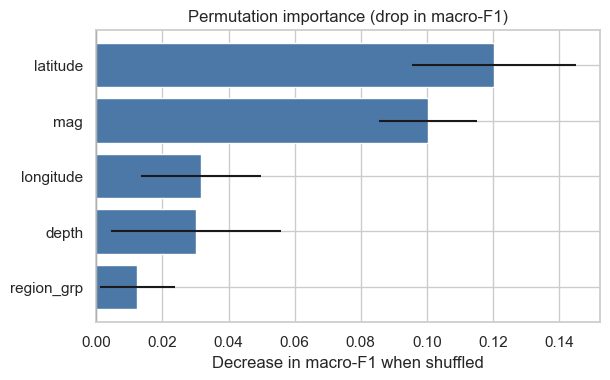

,feature,importance,std
0,latitude,0.120,0.025
3,mag,0.100,0.015
1,longitude,0.032,0.018
2,depth,0.030,0.026
4,region_grp,0.012,0.011


In [22]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(search.best_estimator_, X_te, y_te, scoring="f1_macro", n_repeats=15, random_state=RANDOM_STATE)
imp_df = pd.DataFrame({"feature": X_te.columns, "importance": imp.importances_mean, "std": imp.importances_std}).sort_values("importance")
plt.figure(figsize=(6.5, 3.8))
plt.barh(imp_df["feature"], imp_df["importance"], xerr=imp_df["std"], color="#4c78a8")
plt.axvline(0, color="black", lw=0.8)
plt.title("Permutation importance (drop in macro-F1)"); plt.xlabel("Decrease in macro-F1 when shuffled")
save_fig("feature_importance.png"); plt.show()
imp_df.sort_values("importance", ascending=False).round(3)

**Reading the chart:** `latitude` and `mag` matter most; shuffling either one costs about 0.10–0.12 macro-F1. `longitude` and `depth` matter less, and `region_grp` is close to zero (0.012 ± 0.011, not distinguishable from noise on this test set). That matches the earlier finding that region adds only a little. Latitude and longitude probably act as location proxies that already capture much of what the region label says.

## 10. Save the final model
The model is trained on all events and saved as a single scikit-learn pipeline (preprocessing + Random Forest), which is what the Flask app in `app/` loads.

In [23]:
import joblib
Path("../models").mkdir(exist_ok=True)
deployed = final_model().fit(X_all, y_all)
joblib.dump(deployed, "../models/alert_model.joblib")
print("Saved ../models/alert_model.joblib")

example = pd.DataFrame([{"latitude": 35.7, "longitude": 139.7, "depth": 10.0, "mag": 7.1, "region_grp": "Japan"}])
probs = deployed.predict_proba(example)[0]
print("Example (M7.1, 10 km deep, Japan):", {c: float(p) for c, p in zip(deployed.classes_, probs.round(3))})
print("Predicted alert:", deployed.predict(example)[0])

Saved ../models/alert_model.joblib
Example (M7.1, 10 km deep, Japan): {'green': 0.126, 'orange': 0.216, 'red': 0.404, 'yellow': 0.255}
Predicted alert: red


## 11. Conclusions

**What I found**
1. The original "96% accuracy" was not a real result. 95.7% of events are green, so always answering "green" scores about the same. Its macro-F1 is only 0.24.
2. Handling the imbalance (class weights, stratified evaluation, keeping the large-magnitude events instead of deleting them as outliers) raises cross-validated macro-F1 to about **0.46** and balanced accuracy to **0.51**, versus 0.24 for the always-green baseline and 0.28–0.33 for the unweighted Logistic Regression and Random Forest.
3. As an "any alert" detector, the model reaches PR-AUC **0.60** against a random-guess level of 0.04. At a 0.20 threshold it catches **93%** of real alerts while flagging 19% of events (precision 21%); at 0.30 it catches 90% with precision 26%.
4. On a time-based split (train ≤2019, test 2020–2024), the tuned model scores macro-F1 0.42 and alert PR-AUC 0.53, which is lower than the cross-validated 0.60 and shows that performance on future events will be somewhat worse than the headline numbers, although still far above the ~4.5% alert rate a random guesser would get. Tuning made no meaningful difference: the default settings scored macro-F1 0.41 and PR-AUC 0.54 on the same test years.

**Limitations (worth stating in an interview)**
- Rare classes are still hard: recall is 52% for yellow, 17% for orange and 39% for red, from only 246 / 52 / 33 examples. Per-class numbers for orange and red are noisy.
- These alert levels appear to reflect estimated human and economic impact, which depends on population exposure and building vulnerability. Those are not in this dataset, so there is a natural ceiling on what location, depth and magnitude can predict. The `region` feature is only a rough proxy.
- Feature/threshold choices were made on the same data used for reporting, so treat the numbers as slightly optimistic. The time-based test is the fairer estimate.
- Numbers in this text come from one run with fixed seeds; another scikit-learn version may shift them slightly.

**Next steps:** add population-density / distance-to-coast data, try probability calibration, merge orange+red into a single "high" class, and monitor performance as new events arrive.